# Multimodal Alzheimer's Disease Modelling: v2 (corrected pipeline)

This notebook replaces the experimental pipeline in `dl-project.ipynb`. Every change below fixes a specific problem in v1:

| # | Problem in v1 | Fix in v2 |
|---|---|---|
| 1 | MRI merged with **all** ADNIMERGE visits of a subject → each scan duplicated many times with mismatched clinical rows | Each scan is matched to the **nearest clinical visit in time** (`merge_asof`, ≤ 180 days) |
| 2 | Random scan-level split → same subject/scan in train and test (leakage) | **Subject-level** stratified split (`StratifiedGroupKFold`), train / val / test |
| 3 | Test set used for early stopping | Separate **validation** set; test set touched once |
| 4 | Labels = baseline diagnosis `DX_bl` (constant per subject), SMC mapped to MCI | Label = diagnosis **at the scan's visit** (`DX`: CN / MCI / Dementia) |
| 5 | MMSE / ADAS used as inputs: they are part of how the diagnosis is made (circular) | Main models use **demographics + genetics only**; cognitive scores appear only in an ablation that shows the circularity |
| 6 | No baselines, only accuracy (majority baseline is already 76 %) | Majority + logistic-regression baselines; balanced accuracy, macro-F1, ROC-AUC, subject-bootstrap 95 % CI |
| 7 | "ViViT" had no positional embeddings, no residuals, 43 M parameters | Real **ViViT factorised encoder** (spatial transformer → slice transformer) with position embeddings, pre-norm residual blocks, about 0.6 M parameters |
| 8 | Augmentation applied along the wrong axis, independently per row | One random transform per **whole volume** |
| 9 | No reorientation, background included in normalisation | RAS reorientation, head mask + crop, foreground z-score |
| 10 | Genetics (APOE ε4, GRS) loaded but never used | APOE ε4 + GRS used in the tabular branch |
| 11 | "Temporal" axis was slices of one scan, not time | Section 8 adds a **true longitudinal model** over a subject's successive scans |
| 12 | "Years to AD" = RF regression on visit time; `event` never set (`DX` uses `'Dementia'`, not `'AD'`) | **Cox proportional-hazards** survival model with censoring, C-index, Kaplan–Meier curves |

> **Honest scope:** the image model classifies the diagnosis from *one* scan. The slice axis of a 3-D MRI is treated as the "frame" axis of the video transformer. Disease **progression** is handled by Section 8 (sequences of scans across visits) and Section 9 (survival analysis).

In [1]:
!pip install -q lifelines


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage
from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)

import tensorflow as tf
import keras
from keras import layers

warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
keras.utils.set_random_seed(SEED)   # seeds python, numpy and tensorflow
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.19.1 | Keras 3.7.0 | GPUs: []


In [3]:
# ---------------- configuration ----------------
ON_KAGGLE = os.path.exists('/kaggle/input')
DATA_DIR = os.environ.get('DATA_DIR', '/kaggle/input' if ON_KAGGLE else '.')
OUT_DIR = os.environ.get('OUT_DIR', '/kaggle/working' if ON_KAGGLE else 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)


def find_one(pattern):
    # locate a file/folder anywhere under DATA_DIR (Kaggle and local folder layouts differ)
    hits = sorted(glob.glob(os.path.join(DATA_DIR, '**', pattern), recursive=True), key=len)
    return hits[0] if hits else None


MRI_ROOT = find_one('ADNI')
ADNIMERGE_CSV = find_one('ADNIMERGE*.csv')
GENETICS_CSV = find_one('Final_TOMM40_APOE_GRS.csv')
print('MRI root  :', MRI_ROOT)
print('ADNIMERGE :', ADNIMERGE_CSV)
print('Genetics  :', GENETICS_CSV)

D, H, W = 32, 128, 128             # slices x rows x cols after preprocessing
BRAIN_HEIGHT_MM = 140             # axial extent kept below the top of the head
MAX_DAYS_SCAN_TO_VISIT = 180       # max gap between an MRI and the clinical visit it is matched to
MIN_SUBJECTS_PER_CLASS = 10        # classes with fewer subjects are dropped (cannot be split/evaluated)

QUICK_TEST = os.environ.get('QUICK_TEST') == '1'   # tiny run used only to check the code executes
EPOCHS = 2 if QUICK_TEST else 60
BATCH_SIZE = 8
N_BOOT = 50 if QUICK_TEST else 1000

DX_RANK = {'CN': 0, 'MCI': 1, 'Dementia': 2}

MRI root  : .\MRI Scans-3D\MRI Scans-3D\ADNI
ADNIMERGE : .\data\ADNIMERGE_03May2025.csv
Genetics  : .\data\Final_TOMM40_APOE_GRS.csv


## 1. Index the MRI files (one scan per subject per session)

* Subject IDs are taken from the folder name with a regex, so duplicated download folders such as `141_S_0767(1)` are matched to the right subject instead of being silently dropped.
* `MPRAGE` and `MPRAGE_Repeat` acquired on the same day are near-identical. Keeping both would put near-duplicates on either side of a split, so only one scan per subject per date is kept (the non-repeat one).
* Scanner manufacturer and field strength are read from each scan's JSON sidecar. They are used later to check for a **scanner confound**: if one diagnosis came mostly from one vendor, a model could learn the scanner instead of the disease.

In [4]:
SUBJECT_RE = re.compile(r'(\d{3}_S_\d{4})')
SCAN_META = ['Manufacturer', 'MagneticFieldStrength']

records = []
for path in glob.glob(os.path.join(MRI_ROOT, '*', '*', '*', '*.nii*')):
    subject_dir, scan_type, date_dir = Path(path).parts[-4:-1]
    m = SUBJECT_RE.search(subject_dir)
    if m is None:
        continue
    sidecar = re.sub(r'\.nii(\.gz)?$', '.json', path)
    meta = pd.read_json(sidecar, typ='series') if os.path.exists(sidecar) else pd.Series(dtype=object)
    records.append({'path': path, 'PTID': m.group(1), 'scan_type': scan_type,
                    'scan_date': pd.to_datetime(date_dir[:10]),
                    **{k: meta.get(k) for k in SCAN_META}})

scans = pd.DataFrame(records)
n_files = len(scans)
scans['is_repeat'] = scans['scan_type'].str.contains('repeat', case=False)
scans = (scans.sort_values(['PTID', 'scan_date', 'is_repeat', 'path'])
              .drop_duplicates(['PTID', 'scan_date'])
              .drop(columns='is_repeat')
              .reset_index(drop=True))
scans['MagneticFieldStrength'] = np.where(scans['MagneticFieldStrength'] < 2, '1.5T', '3T')
scans['scan_idx'] = np.arange(len(scans))      # row of this scan in X_all (Section 2)
print(f'{n_files} NIfTI files -> {len(scans)} unique scanning sessions from {scans.PTID.nunique()} subjects')
print('Scans per subject:', scans.groupby('PTID').size().value_counts().sort_index().to_dict())
print(scans.groupby(SCAN_META, dropna=False).size().rename('scans').to_string())

518 NIfTI files -> 487 unique scanning sessions from 227 subjects
Scans per subject: {1: 111, 2: 25, 3: 52, 4: 31, 5: 4, 6: 3, 8: 1}
Manufacturer  MagneticFieldStrength
Philips       1.5T                      27
              3T                        32
Siemens       1.5T                     274
              3T                       154


## 2. MRI preprocessing

For each scan:
1. **Reorient to RAS** (`as_closest_canonical`), so that axis 2 is always inferior → superior. v1 assumed this without checking.
2. **Head mask**: intensity threshold, morphological opening, largest connected component, hole filling. Then **crop** to the mask's bounding box, which removes empty background slices.
3. **Axial crop** to the top `BRAIN_HEIGHT_MM` of the head, measured in millimetres from the voxel spacing. This removes neck and face slices consistently even when scans have different fields of view.
4. **Foreground z-score** with percentile clipping. Background is set to a constant, so air does not dominate the statistics.
5. **Resample** to a fixed `D × H × W` grid laid out as (slices, rows, cols).

All unique scans are preprocessed once and cached to disk (`X_all`). Full skull-stripping and registration to MNI space (e.g. SynthStrip + ANTs) would be better still. See *Limitations*.

In [5]:
def _fit_shape(vol, shape):
    # crop / zero-pad each axis so the volume has exactly `shape` (zoom can be off by one voxel)
    out = np.zeros(shape, dtype=vol.dtype)
    sl = tuple(slice(0, min(a, b)) for a, b in zip(vol.shape, shape))
    out[sl] = vol[sl]
    return out


def preprocess_volume(path, out_shape=(D, H, W)):
    img = nib.as_closest_canonical(nib.load(path))
    vol = np.asarray(img.dataobj, dtype=np.float32)
    if vol.ndim == 4:
        vol = vol[..., 0]
    vol = np.nan_to_num(vol)

    mask = vol > 0.1 * np.percentile(vol, 99.5)
    mask = ndimage.binary_opening(mask, iterations=2)
    lab, n = ndimage.label(mask)
    if n > 1:
        sizes = ndimage.sum(mask, lab, range(1, n + 1))
        mask = lab == (np.argmax(sizes) + 1)
    mask = ndimage.binary_fill_holes(mask)

    coords = np.argwhere(mask)
    lo, hi = coords.min(0), coords.max(0) + 1
    box = tuple(slice(a, b) for a, b in zip(lo, hi))
    # keep only the top BRAIN_HEIGHT_MM of the head (vertex -> below cerebellum): drops neck and face slices
    z_vox = int(round(BRAIN_HEIGHT_MM / img.header.get_zooms()[2]))
    box = box[:2] + (slice(max(lo[2], hi[2] - z_vox), hi[2]),)
    vol, mask = vol[box], mask[box]

    fg = vol[mask]
    p_lo, p_hi = np.percentile(fg, [0.5, 99.5])
    vol = np.clip(vol, p_lo, p_hi)
    fg = vol[mask]
    vol = (vol - fg.mean()) / (fg.std() + 1e-6)
    vol[~mask] = vol[mask].min()                           # background = darkest tissue value

    vol = np.transpose(vol, (2, 1, 0))                     # RAS (x, y, z) -> (slices, rows, cols)
    vol = ndimage.zoom(vol, np.array(out_shape) / vol.shape, order=1)
    return _fit_shape(vol, out_shape).astype(np.float16)


cache_file = os.path.join(OUT_DIR, f'mri_cache_{D}x{H}x{W}_{BRAIN_HEIGHT_MM}mm.npz')
rel_paths = np.array([os.path.relpath(p, MRI_ROOT) for p in scans['path']])   # portable cache key
if os.path.exists(cache_file) and np.array_equal(np.load(cache_file)['paths'], rel_paths):
    X_all = np.load(cache_file)['X']
    print('Loaded cached volumes', X_all.shape)
else:
    X_all = np.zeros((len(scans), D, H, W, 1), dtype=np.float16)
    for i, p in enumerate(scans['path']):
        X_all[i, ..., 0] = preprocess_volume(p)
        if (i + 1) % 25 == 0 or i + 1 == len(scans):
            print(f'  preprocessed {i + 1}/{len(scans)}', flush=True)
    np.savez(cache_file, X=X_all, paths=rel_paths)
print('X_all:', X_all.shape, X_all.dtype, f'{X_all.nbytes / 1e9:.2f} GB')

Loaded cached volumes (487, 32, 128, 128, 1)
X_all: (487, 32, 128, 128, 1) float16 0.51 GB


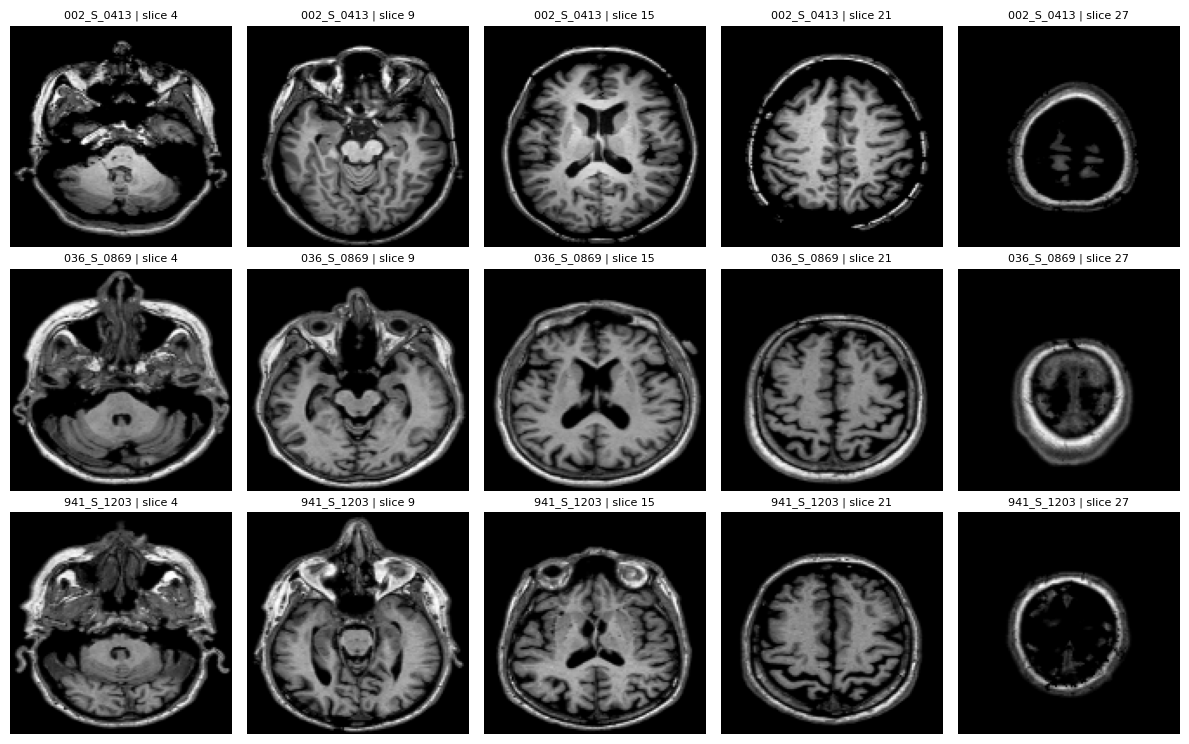

In [6]:
# Sanity check: 5 slices from 3 different scans after preprocessing
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for r, i in enumerate(np.linspace(0, len(X_all) - 1, 3).astype(int)):
    for c, s in enumerate(np.linspace(4, D - 5, 5).astype(int)):
        axes[r, c].imshow(X_all[i, s, :, :, 0].astype(np.float32), cmap='gray', origin='lower')
        axes[r, c].set_title(f"{scans.PTID[i]} | slice {s}", fontsize=8)
        axes[r, c].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'preprocessing_check.png'), dpi=80); plt.show()

## 3. Match each scan to the clinical visit closest in time

v1 merged on subject ID only. ADNIMERGE has one row **per visit**, so every scan was copied once per visit, with clinical values from other dates. Here `merge_asof` attaches each scan to the single nearest visit that has a diagnosis, provided it is within `MAX_DAYS_SCAN_TO_VISIT` days.

The label is `DX`, the diagnosis **at that visit**. ADNIMERGE codes it as `CN` / `MCI` / `Dementia`. `DX_bl` is only the baseline diagnosis and uses `AD`.

In [7]:
adni = pd.read_csv(ADNIMERGE_CSV, low_memory=False)
adni['EXAMDATE'] = pd.to_datetime(adni['EXAMDATE'], errors='coerce')
adni = adni.dropna(subset=['EXAMDATE'])
adni['AGE_AT_VISIT'] = adni['AGE'] + adni['Years_bl']
adni['SEX_F'] = (adni['PTGENDER'] == 'Female').astype(float)
for col in ['MMSE', 'ADAS11', 'ADAS13', 'APOE4', 'PTEDUCAT']:
    adni[col] = pd.to_numeric(adni[col], errors='coerce')
adni_dx = adni[adni['DX'].isin(DX_RANK)].copy()   # visits that have a diagnosis
print('ADNIMERGE diagnosis values:', adni['DX'].value_counts(dropna=False).to_dict())

genetics = (pd.read_csv(GENETICS_CSV)
              .rename(columns={'IID': 'PTID'})[['PTID', 'GRS']]
              .drop_duplicates('PTID'))

visit_cols = ['PTID', 'RID', 'VISCODE', 'EXAMDATE', 'DX', 'AGE_AT_VISIT', 'SEX_F', 'PTEDUCAT',
              'APOE4', 'MMSE', 'ADAS11', 'ADAS13']
data = pd.merge_asof(scans.sort_values('scan_date'),
                     adni_dx[visit_cols].sort_values('EXAMDATE'),
                     left_on='scan_date', right_on='EXAMDATE', by='PTID',
                     direction='nearest', tolerance=pd.Timedelta(days=MAX_DAYS_SCAN_TO_VISIT))
n_unmatched = data['DX'].isna().sum()
data = data.dropna(subset=['DX']).merge(genetics, on='PTID', how='left')
print(f'{n_unmatched} scans had no diagnosed visit within {MAX_DAYS_SCAN_TO_VISIT} days and were dropped')

# Drop classes with too few subjects to appear in train, val and test
subj_per_class = data.groupby('DX')['PTID'].nunique()
print('Subjects per class:', subj_per_class.to_dict())
keep = [c for c in DX_RANK if subj_per_class.get(c, 0) >= MIN_SUBJECTS_PER_CLASS]
if len(keep) < len(subj_per_class):
    print('Dropping classes with too few subjects:', sorted(set(subj_per_class.index) - set(keep)))
data = data[data['DX'].isin(keep)].sort_values(['PTID', 'scan_date']).reset_index(drop=True)

CLASS_NAMES = keep
N_CLASSES = len(CLASS_NAMES)
data['label'] = data['DX'].map({c: i for i, c in enumerate(CLASS_NAMES)})
y = data['label'].to_numpy()
groups = data['PTID'].to_numpy()
X_mri = X_all[data['scan_idx'].to_numpy()]          # MRI volumes aligned with `data` rows

print(f'\nFinal dataset: {len(data)} scans, {data.PTID.nunique()} subjects')
print('Scans per class:', data['DX'].value_counts().to_dict())
print(f"Median |scan - visit| gap: {(data.scan_date - data.EXAMDATE).abs().dt.days.median():.0f} days")

ADNIMERGE diagnosis values: {'MCI': 4989, nan: 4963, 'CN': 4020, 'Dementia': 2449}
0 scans had no diagnosed visit within 180 days and were dropped
Subjects per class: {'CN': 73, 'Dementia': 18, 'MCI': 151}

Final dataset: 487 scans, 227 subjects
Scans per class: {'MCI': 280, 'CN': 185, 'Dementia': 22}
Median |scan - visit| gap: 5 days


### Feature sets

* **`DEMO_GENETIC`**: age at the visit, sex, years of education, APOE ε4 allele count and the TOMM40/APOE genetic risk score. None of these is used to make the diagnosis, so they are fair predictors.
* **`COGNITIVE`**: MMSE, ADAS-11 and ADAS-13. The CN / MCI / Dementia labels are assigned largely from these cognitive tests. Feeding them to a classifier is close to predicting the label from itself. They are used **only** in an ablation (Section 5) to make that point explicit.

In [8]:
DEMO_GENETIC = ['AGE_AT_VISIT', 'SEX_F', 'PTEDUCAT', 'APOE4', 'GRS']
COGNITIVE = ['MMSE', 'ADAS11', 'ADAS13']
display(data[DEMO_GENETIC + COGNITIVE].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
AGE_AT_VISIT,487.0,74.61,6.69,55.94,70.80,74.40,78.99,90.64
SEX_F,487.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
PTEDUCAT,487.0,15.64,3.07,6.00,14.00,16.00,18.00,20.00
APOE4,487.0,0.42,0.60,0.00,0.00,0.00,1.00,2.00
GRS,487.0,0.61,0.82,0.00,0.00,0.00,1.48,2.96
MMSE,487.0,27.95,2.19,17.00,27.00,29.00,30.00,30.00
ADAS11,487.0,8.71,5.12,0.00,5.00,7.33,11.67,25.67
ADAS13,486.0,13.89,7.95,0.00,7.33,12.33,19.00,38.33


## 4. Subject-level train / validation / test split

All scans of a subject go to the same split. The split is stratified by label: 64 % train, 16 % validation (early stopping), 20 % test (used once).

In [9]:
def subject_split(y, groups, seed=SEED):
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trval, test = next(outer.split(np.zeros(len(y)), y, groups))
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    tr, va = next(inner.split(np.zeros(len(trval)), y[trval], groups[trval]))
    return trval[tr], trval[va], test

train_idx, val_idx, test_idx = subject_split(y, groups)
s_tr, s_va, s_te = (set(groups[i]) for i in (train_idx, val_idx, test_idx))
assert not (s_tr & s_va or s_tr & s_te or s_va & s_te), 'subject leakage between splits'

split_table = pd.DataFrame({name: pd.Series(y[idx]).map(dict(enumerate(CLASS_NAMES))).value_counts()
                            for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]})
split_table.loc['subjects'] = [len(s_tr), len(s_va), len(s_te)]
display(split_table.fillna(0).astype(int))

,train,val,test
CN,111,42,32
Dementia,14,4,4
MCI,179,37,64
subjects,145,36,46


In [10]:
# Scanner confound check: is diagnosis associated with scanner vendor / field strength?
from scipy.stats import chi2_contingency
for col in SCAN_META:
    ct = pd.crosstab(data[col].fillna('unknown'), data['DX'])
    p = chi2_contingency(ct)[1] if ct.shape[0] > 1 else float('nan')
    display(ct)
    print(f'chi-square p-value ({col} vs DX): {p:.3g}  -> a small p means the scanner is a possible confound')

DX,CN,Dementia,MCI
Manufacturer,,,
Philips,28,5,26
Siemens,157,17,254


chi-square p-value (Manufacturer vs DX): 0.0494  -> a small p means the scanner is a possible confound


DX,CN,Dementia,MCI
MagneticFieldStrength,,,
1.5T,133,15,153
3T,52,7,127


chi-square p-value (MagneticFieldStrength vs DX): 0.000733  -> a small p means the scanner is a possible confound


## 5. Baselines

Any deep model has to beat these to be worth its complexity:
* **Majority class**: always predict the most common training label.
* **Logistic regression, demographics + genetics**: the honest tabular baseline.
* **Logistic regression + cognitive scores**: an ablation. A high score here shows how much the cognitive tests encode the label (circularity), not that the problem is solved.

Every model is reported with balanced accuracy, macro-F1 and ROC-AUC. A 95 % CI comes from bootstrapping **test subjects**.

In [11]:
RESULTS = []

def evaluate(name, proba, idx=test_idx, labels=None, task='3-class'):
    labels = y if labels is None else labels
    y_true, y_pred = labels[idx], proba.argmax(1)
    auc = (roc_auc_score(y_true, proba[:, 1]) if proba.shape[1] == 2
           else roc_auc_score(y_true, proba, multi_class='ovr', average='macro', labels=list(range(proba.shape[1]))))
    # bootstrap over subjects (scans of one subject are not independent)
    rng = np.random.default_rng(SEED)
    g = groups[idx]
    subj = np.unique(g)
    rows_of = {s: np.flatnonzero(g == s) for s in subj}
    boot = []
    for _ in range(N_BOOT):
        ix = np.concatenate([rows_of[s] for s in rng.choice(subj, len(subj), replace=True)])
        boot.append(balanced_accuracy_score(y_true[ix], y_pred[ix]))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    res = {'task': task, 'model': name,
           'balanced_acc': balanced_accuracy_score(y_true, y_pred),
           'bal_acc_95CI': f'[{lo:.3f}, {hi:.3f}]',
           'macro_f1': f1_score(y_true, y_pred, average='macro'),
           'roc_auc': auc,
           'accuracy': (y_true == y_pred).mean()}
    RESULTS.append(res)
    print(f"{name:45s} bal_acc={res['balanced_acc']:.3f} {res['bal_acc_95CI']}  "
          f"macro_f1={res['macro_f1']:.3f}  auc={auc:.3f}")
    return res


trval_idx = np.concatenate([train_idx, val_idx])

# majority class
majority = np.bincount(y[trval_idx], minlength=N_CLASSES).argmax()
evaluate('Majority class', np.eye(N_CLASSES)[np.full(len(test_idx), majority)])

def logreg(features):
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=5000))

for name, feats in [('LogReg: demographics + genetics', DEMO_GENETIC),
                    ('LogReg: demo + genetics + COGNITIVE (ablation)', DEMO_GENETIC + COGNITIVE)]:
    clf = logreg(feats).fit(data.iloc[trval_idx][feats], y[trval_idx])
    evaluate(name, clf.predict_proba(data.iloc[test_idx][feats]))

Majority class                                bal_acc=0.333 [0.333, 0.333]  macro_f1=0.260  auc=0.500


C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: 

C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: 

LogReg: demographics + genetics               bal_acc=0.552 [0.373, 0.740]  macro_f1=0.355  auc=0.648


LogReg: demo + genetics + COGNITIVE (ablation) bal_acc=0.797 [0.730, 0.862]  macro_f1=0.570  auc=0.901


C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: 

In [12]:
# The baselines are cheap, so also report 5-fold subject-grouped cross-validation (mean ± sd),
# which is far more stable than a single split.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, feats in [('demographics + genetics', DEMO_GENETIC), ('+ cognitive (ablation)', DEMO_GENETIC + COGNITIVE)]:
    scores = []
    for tr, te in cv.split(np.zeros(len(y)), y, groups):
        clf = logreg(feats).fit(data.iloc[tr][feats], y[tr])
        scores.append(balanced_accuracy_score(y[te], clf.predict(data.iloc[te][feats])))
    print(f'5-fold grouped CV, LogReg {name:28s}: balanced acc = {np.mean(scores):.3f} ± {np.std(scores):.3f}')

5-fold grouped CV, LogReg demographics + genetics     : balanced acc = 0.467 ± 0.057
5-fold grouped CV, LogReg + cognitive (ablation)      : balanced acc = 0.745 ± 0.043


## 6. ViViT factorised encoder

Architecture: the *factorised encoder* (Model 2) from Arnab et al., *ViViT: A Video Vision Transformer*, ICCV 2021. The "frames" are the axial slices of the 3-D scan.

```
MRI (32 slices x 128 x 128)
  └─ patch embedding: Conv3D kernel (1,16,16), stride (1,16,16) -> 32 slices x 64 patches x 128-d
  └─ + learnable spatial position embedding
  └─ SPATIAL transformer (2 pre-norm blocks), weights shared by all slices -> mean-pool -> 1 token per slice
  └─ + learnable slice position embedding   (slice order now matters, unlike v1)
  └─ SLICE transformer (2 pre-norm blocks) -> mean-pool -> 128-d MRI embedding
Tabular (demographics + genetics) -> Dense(32)
  └─ concat -> Dense(64) -> softmax
```

About 0.6 M parameters, compared with 43 M in v1, which was far too many for a few hundred scans. The data augmentation (small in-plane shift + intensity jitter) applies **one** random transform to the whole volume. Left–right flips are deliberately not used, because AD atrophy is often asymmetric.

In [13]:
class PositionEmbedding(layers.Layer):
    # learnable embedding over the last two axes (tokens, channels), broadcast over the leading axes
    def build(self, input_shape):
        self.pos = self.add_weight(name='pos', shape=tuple(input_shape[-2:]),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02))

    def call(self, x):
        return x + self.pos


def transformer_block(x, dim, heads, mlp_dim, dropout):
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.MultiHeadAttention(num_heads=heads, key_dim=dim // heads, dropout=dropout)(h, h)
    x = layers.Add()([x, h])
    h = layers.LayerNormalization(epsilon=1e-6)(x)
    h = layers.Dense(mlp_dim, activation='gelu')(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(dim)(h)
    return layers.Add()([x, h])


def fusion_head(z, mri_in, num_classes, n_tabular, tab_skip=False, mri_dropout=0.0):
    # classifier on top of the MRI embedding z, optionally fused with a tabular input.
    # tab_skip adds a direct linear tabular -> logits path, so a noisy MRI embedding cannot stop the
    # model from using the tabular features (it can then always fall back to logistic regression).
    inputs = [mri_in]
    if n_tabular:
        tab_in = keras.Input((n_tabular,), name='tab')
        t = layers.Dense(32, activation='gelu')(tab_in)
        t = layers.Dropout(0.2)(t)
        z = layers.Concatenate()([layers.Dropout(mri_dropout)(z), t])
        inputs.append(tab_in)
    z = layers.Dropout(0.3)(z)
    z = layers.Dense(64, activation='gelu')(z)
    z = layers.Dropout(0.3)(z)
    logits = layers.Dense(num_classes)(z)
    if n_tabular and tab_skip:
        logits = layers.Add()([logits, layers.Dense(num_classes, name='tab_linear')(tab_in)])
    return inputs, layers.Activation('softmax')(logits)


def build_vivit(num_classes, n_tabular=0, patch=16, dim=128, heads=4, mlp_dim=256,
                spatial_depth=2, slice_depth=2, dropout=0.1, cnn_stem=False, tab_skip=False):
    mri_in = keras.Input((D, H, W, 1), name='mri')
    if cnn_stem:
        # hybrid: three 3-D conv blocks (each halves rows/cols) give the transformer local,
        # translation-equivariant features instead of raw pixels, so far less data is needed
        x = mri_in
        for ch in (16, 32, 64):
            x = layers.Conv3D(ch, 3, strides=(1, 2, 2), padding='same', use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation('gelu')(x)
        n_patches = (H // 16) * (W // 16)               # 2x2 tokens on the 16x16 feature map
        x = layers.Conv3D(dim, (1, 2, 2), strides=(1, 2, 2), name='patch_embed')(x)
    else:
        n_patches = (H // patch) * (W // patch)
        x = layers.Conv3D(dim, (1, patch, patch), strides=(1, patch, patch), name='patch_embed')(mri_in)
    x = layers.Reshape((D, n_patches, dim))(x)
    x = PositionEmbedding(name='spatial_pos')(x)

    tokens = keras.Input((n_patches, dim))
    t = tokens
    for _ in range(spatial_depth):
        t = transformer_block(t, dim, heads, mlp_dim, dropout)
    t = layers.LayerNormalization(epsilon=1e-6)(t)
    t = layers.GlobalAveragePooling1D()(t)
    spatial_encoder = keras.Model(tokens, t, name='spatial_encoder')
    x = layers.TimeDistributed(spatial_encoder, name='per_slice')(x)       # (D, dim)

    x = PositionEmbedding(name='slice_pos')(x)
    for _ in range(slice_depth):
        x = transformer_block(x, dim, heads, mlp_dim, dropout)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    z = layers.GlobalAveragePooling1D(name='mri_embedding')(x)
    inputs, out = fusion_head(z, mri_in, num_classes, n_tabular, tab_skip, mri_dropout=0.5 if tab_skip else 0.0)
    return keras.Model(inputs, out, name=('hybrid_' if cnn_stem else '') + 'vivit' + ('_fusion' if n_tabular else '_mri'))


build_vivit(N_CLASSES, n_tabular=len(DEMO_GENETIC)).summary()

Model: "vivit_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mri (InputLayer)    │ (None, 32, 128,   │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embed         │ (None, 32, 8, 8,  │     32,896 │ mri[0][0]         │
│ (Conv3D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 32, 64,    │          0 │ patch_embed[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_pos         │ (None, 32, 64,    │      8,192 │ reshape[0][0]     │
│ (PositionEmbedding) │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ per_slice           │ (None, 32, 128)   │    265,216 │ spatial_pos[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ slice_pos           │ (None, 32, 128)   │      4,096 │ per_slice[0][0]   │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 128)   │        256 │ slice_pos[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 32, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 32, 128)   │          0 │ slice_pos[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 128)   │        256 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32, 256)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32, 128)   │     32,896 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 32, 128)   │          0 │ add_4[0][0],      │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 128)   │        256 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 32, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 32, 128)   │          0 │ add_5[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 32, 128)   │        256 │ add_6[0][0]     

 Total params: 586,307 (2.24 MB)

 Trainable params: 586,307 (2.24 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
def augment(inputs, label):
    v = tf.cast(inputs['mri'], tf.float32)                       # (D, H, W, 1): one transform per volume
    shift = tf.random.uniform([2], -8, 9, dtype=tf.int32)
    v = tf.roll(v, shift=shift, axis=[1, 2])                     # same in-plane shift for every slice
    v = v * tf.random.uniform([], 0.9, 1.1) + tf.random.uniform([], -0.1, 0.1)
    return {**inputs, 'mri': v}, label


def to_float(inputs, label):
    return {**inputs, 'mri': tf.cast(inputs['mri'], tf.float32)}, label


def make_dataset(idx, tab=None, training=False, labels=None):
    labels = y if labels is None else labels
    inputs = {'mri': X_mri[idx]}
    if tab is not None:
        inputs['tab'] = tab.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((inputs, labels[idx]))
    if training:
        ds = ds.shuffle(len(idx), seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(to_float, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def train_vivit(name, use_tabular):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    tabs = [None, None, None]
    if use_tabular:   # imputer + scaler fitted on the TRAINING split only
        prep = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler())
        prep.fit(data.iloc[train_idx][DEMO_GENETIC])
        tabs = [prep.transform(data.iloc[idx][DEMO_GENETIC]) for idx in (train_idx, val_idx, test_idx)]

    model = build_vivit(N_CLASSES, n_tabular=tabs[0].shape[1] if use_tabular else 0)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4, clipnorm=1.0),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cw = compute_class_weight('balanced', classes=np.arange(N_CLASSES), y=y[train_idx])
    history = model.fit(
        make_dataset(train_idx, tabs[0], training=True),
        validation_data=make_dataset(val_idx, tabs[1]),
        epochs=EPOCHS,
        class_weight=dict(enumerate(cw)),
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)],
        verbose=2)
    proba = model.predict(make_dataset(test_idx, tabs[2]), verbose=0)
    evaluate(name, proba)
    return model, history, proba

In [15]:
vivit_mri, hist_mri, proba_mri = train_vivit('ViViT: MRI only', use_tabular=False)

Epoch 1/60


38/38 - 69s - 2s/step - accuracy: 0.4112 - loss: 1.7831 - val_accuracy: 0.4458 - val_loss: 0.9525 - learning_rate: 3.0000e-04


Epoch 2/60


38/38 - 9s - 234ms/step - accuracy: 0.4309 - loss: 1.4779 - val_accuracy: 0.4458 - val_loss: 0.9596 - learning_rate: 3.0000e-04


Epoch 3/60


...

Epoch 12/60


38/38 - 8s - 219ms/step - accuracy: 0.4309 - loss: 1.2350 - val_accuracy: 0.4458 - val_loss: 0.9452 - learning_rate: 7.5000e-05


Epoch 13/60


38/38 - 8s - 216ms/step - accuracy: 0.5099 - loss: 1.1739 - val_accuracy: 0.4458 - val_loss: 0.9598 - learning_rate: 7.5000e-05


ViViT: MRI only                               bal_acc=0.349 [0.333, 0.374]  macro_f1=0.195  auc=0.573


In [16]:
vivit_fus, hist_fus, proba_fus = train_vivit('ViViT: MRI + demographics + genetics', use_tabular=True)

Epoch 1/60


38/38 - 70s - 2s/step - accuracy: 0.4408 - loss: 1.6512 - val_accuracy: 0.4458 - val_loss: 1.0296 - learning_rate: 3.0000e-04


Epoch 2/60


38/38 - 13s - 330ms/step - accuracy: 0.4605 - loss: 1.5398 - val_accuracy: 0.4940 - val_loss: 0.9333 - learning_rate: 3.0000e-04


Epoch 3/60


...

Epoch 12/60


38/38 - 13s - 335ms/step - accuracy: 0.4868 - loss: 1.1261 - val_accuracy: 0.4940 - val_loss: 0.9950 - learning_rate: 7.5000e-05


Epoch 13/60


38/38 - 13s - 334ms/step - accuracy: 0.5197 - loss: 1.1705 - val_accuracy: 0.5422 - val_loss: 1.0091 - learning_rate: 7.5000e-05


ViViT: MRI + demographics + genetics          bal_acc=0.359 [0.338, 0.399]  macro_f1=0.216  auc=0.534


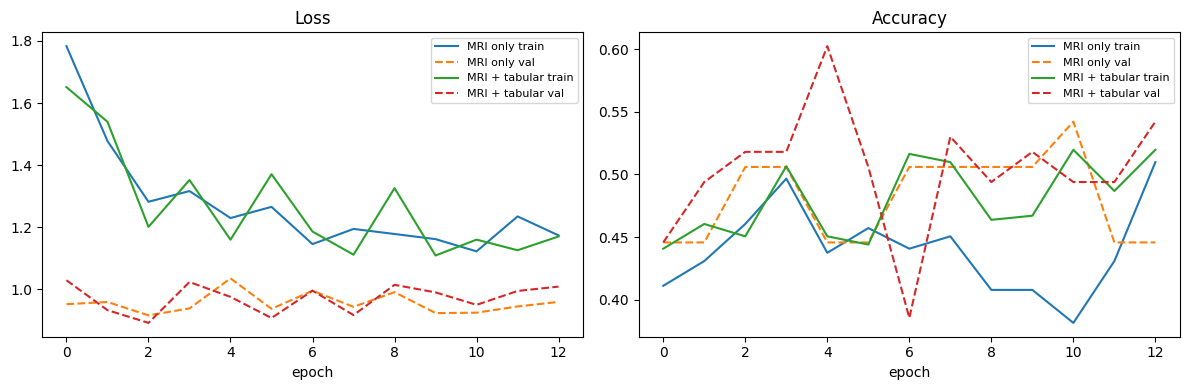

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, label in [(hist_mri, 'MRI only'), (hist_fus, 'MRI + tabular')]:
    axes[0].plot(hist.history['loss'], label=f'{label} train')
    axes[0].plot(hist.history['val_loss'], '--', label=f'{label} val')
    axes[1].plot(hist.history['accuracy'], label=f'{label} train')
    axes[1].plot(hist.history['val_accuracy'], '--', label=f'{label} val')
axes[0].set_title('Loss'); axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'learning_curves.png')); plt.show()

## 7. Results

Read the table against the baselines:
* If the ViViT does not clearly beat **LogReg: demographics + genetics**, the MRI branch adds little. That is a legitimate finding and should be reported, not hidden.
* The **cognitive ablation** row is not a fair competitor. It shows how much of the label is already contained in the test scores.
* Look at **balanced accuracy and AUC**, not raw accuracy. With imbalanced classes, accuracy rewards predicting the majority class.

balanced_acc  \
task    model                                                          
3-class Majority class                                         0.333   
        LogReg: demographics + genetics                        0.552   
        LogReg: demo + genetics + COGNITIVE (ablation)         0.797   
        ViViT: MRI only                                        0.349   
        ViViT: MRI + demographics + genetics                   0.359   

                                                          bal_acc_95CI  \
task    model                                                            
3-class Majority class                                  [0.333, 0.333]   
        LogReg: demographics + genetics                 [0.373, 0.740]   
        LogReg: demo + genetics + COGNITIVE (ablation)  [0.730, 0.862]   
        ViViT: MRI only                                 [0.333, 0.374]   
        ViViT: MRI + demographics + genetics            [0.338, 0.399]   

                                                        macro_f1  roc_auc  \
task    model                                                               
3-class Majority class                                     0.260    0.500   
        LogReg: demographics + genetics                    0.355    0.648   
        LogReg: demo + genetics + COGNITIVE (ablation)     0.570    0.901   
        ViViT: MRI only                                    0.195    0.573   
        ViViT: MRI + demographics + genetics               0.216    0.534   

                                                        accuracy  
task    model                                                     
3-class Majority class                                      0.64  
        LogReg: demographics + genetics                     0.44  
        LogReg: demo + genetics + COGNITIVE (ablation)      0.64  
        ViViT: MRI only                                     0.35  
        ViViT: MRI + demographics + genetics                0.37

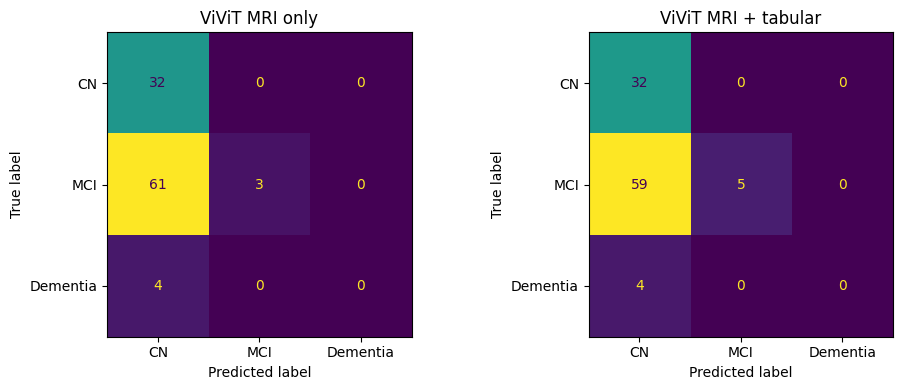

              precision    recall  f1-score   support

          CN       0.34      1.00      0.50        32
         MCI       1.00      0.08      0.14        64
    Dementia       0.00      0.00      0.00         4

    accuracy                           0.37       100
   macro avg       0.45      0.36      0.22       100
weighted avg       0.75      0.37      0.25       100



In [18]:
results = pd.DataFrame(RESULTS).set_index(['task', 'model']).round(3)
display(results)
results.to_csv(os.path.join(OUT_DIR, 'results_v2.csv'))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (proba, title) in zip(axes, [(proba_mri, 'ViViT MRI only'), (proba_fus, 'ViViT MRI + tabular')]):
    ConfusionMatrixDisplay.from_predictions(y[test_idx], proba.argmax(1), display_labels=CLASS_NAMES,
                                            ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'confusion_matrices.png')); plt.show()

print(classification_report(y[test_idx], proba_fus.argmax(1), target_names=CLASS_NAMES, zero_division=0))

## 7b. Why the ViViT failed, and fixes

Both ViViT models in Section 6 collapsed to predicting a single class. Three causes, each with a fix:

| Cause | Fix tested here |
|---|---|
| A transformer trained from scratch has no built-in image prior and needs far more than about 300 scans | **Hybrid CNN + ViViT**: three 3-D conv blocks before the ViViT encoder (a standard remedy for ViTs on small data) |
| Early stopping watched the *unweighted* validation loss, which is lowest when the model predicts the majority class | Early stopping and weight restoring on **validation balanced accuracy** |
| In the fused model the noisy 128-d MRI embedding swamped the 5 tabular features | A **direct linear tabular → logits path** and dropout on the MRI branch |
| Diagnosis is associated with field strength (Section 3) | **Field strength (3T vs 1.5T)** added to the tabular inputs, so the model does not have to infer it from the image |

Two further checks:
* **3-D CNN baseline**: does the MRI carry learnable signal at all?
* **Binary task, CN vs cognitively impaired (MCI + Dementia)**: Dementia has only about 20 subjects, which makes the 3-class task very noisy. CN-vs-impaired is a common ADNI framing.

Everything uses the same subject-level split, so all rows in the final table are directly comparable.

In [19]:
data['FIELD_3T'] = (data['MagneticFieldStrength'] == '3T').astype(float)
TAB_FEATURES = DEMO_GENETIC + ['FIELD_3T']
y_bin = (y > 0).astype(int)                       # 0 = CN, 1 = MCI or Dementia
BIN_NAMES = ['CN', 'Impaired']
EPOCHS_7B = 2 if QUICK_TEST else 40


class BestBalancedAccuracy(keras.callbacks.Callback):
    # early stopping + best-weight restore on validation balanced accuracy (AUC breaks ties)
    def __init__(self, val_ds, y_val, patience=10):
        super().__init__()
        self.val_ds, self.y_val, self.patience = val_ds, y_val, patience

    def on_train_begin(self, logs=None):
        self.best, self.best_weights, self.wait = -np.inf, None, 0

    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.val_ds, verbose=0)
        auc = (roc_auc_score(self.y_val, p[:, 1]) if p.shape[1] == 2 else
               roc_auc_score(self.y_val, p, multi_class='ovr', average='macro', labels=list(range(p.shape[1]))))
        bal = balanced_accuracy_score(self.y_val, p.argmax(1))
        print(f'    epoch {epoch + 1:2d}  train_loss={logs["loss"]:.3f}  val_bal_acc={bal:.3f}  val_auc={auc:.3f}',
              flush=True)
        if bal + 1e-3 * auc > self.best:
            self.best, self.best_weights, self.wait = bal + 1e-3 * auc, self.model.get_weights(), 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def fit_eval(name, build_fn, labels, task, use_tab, lr=3e-4):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    n_classes = int(labels.max()) + 1
    tabs = [None, None, None]
    if use_tab:   # imputer + scaler fitted on the TRAINING split only
        prep = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler())
        prep.fit(data.iloc[train_idx][TAB_FEATURES])
        tabs = [prep.transform(data.iloc[idx][TAB_FEATURES]) for idx in (train_idx, val_idx, test_idx)]
    model = build_fn(n_classes, tabs[0].shape[1] if use_tab else 0)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cw = compute_class_weight('balanced', classes=np.arange(n_classes), y=labels[train_idx])
    stopper = BestBalancedAccuracy(make_dataset(val_idx, tabs[1], labels=labels), labels[val_idx])
    model.fit(make_dataset(train_idx, tabs[0], training=True, labels=labels), epochs=EPOCHS_7B,
              class_weight=dict(enumerate(cw)), callbacks=[stopper], verbose=0)
    proba = model.predict(make_dataset(test_idx, tabs[2], labels=labels), verbose=0)
    evaluate(name, proba, labels=labels, task=task)
    return model, proba


def build_cnn3d(num_classes, n_tabular=0):
    mri_in = keras.Input((D, H, W, 1), name='mri')
    x = mri_in
    for ch, pool in [(16, (1, 2, 2)), (32, (2, 2, 2)), (64, (2, 2, 2)), (128, (2, 2, 2))]:
        x = layers.Conv3D(ch, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling3D(pool)(x)
    z = layers.GlobalAveragePooling3D(name='mri_embedding')(x)
    inputs, out = fusion_head(z, mri_in, num_classes, n_tabular, tab_skip=n_tabular > 0, mri_dropout=0.5)
    return keras.Model(inputs, out, name='cnn3d' + ('_fusion' if n_tabular else '_mri'))


def hybrid(num_classes, n_tabular=0):
    return build_vivit(num_classes, n_tabular=n_tabular, cnn_stem=True, tab_skip=n_tabular > 0)


print('Hybrid CNN+ViViT parameters:', hybrid(N_CLASSES).count_params())
print('3-D CNN parameters         :', build_cnn3d(N_CLASSES).count_params())

Hybrid CNN+ViViT parameters:

 654067
3-D CNN parameters         : 300147


In [20]:
# ---------- 3-class (CN / MCI / Dementia) ----------
clf = logreg(TAB_FEATURES).fit(data.iloc[trval_idx][TAB_FEATURES], y[trval_idx])
evaluate('LogReg: demo + genetics + field strength', clf.predict_proba(data.iloc[test_idx][TAB_FEATURES]))

MRI_ONLY_3CLASS = {'ViViT (Section 6)': vivit_mri}
for name, fn, use_tab in [('Hybrid CNN+ViViT: MRI only', hybrid, False),
                          ('Hybrid CNN+ViViT: MRI + tabular', hybrid, True),
                          ('3-D CNN: MRI only', build_cnn3d, False)]:
    print(f'\n>>> [3-class] {name}', flush=True)
    model, _ = fit_eval(name, fn, y, '3-class', use_tab)
    if not use_tab:
        MRI_ONLY_3CLASS[name] = model

C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: 

LogReg: demo + genetics + field strength      bal_acc=0.458 [0.298, 0.654]  macro_f1=0.366  auc=0.649

>>> [3-class] Hybrid CNN+ViViT: MRI only


C:\Users\Pc\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


    epoch  1  train_loss=1.526  val_bal_acc=0.333  val_auc=0.551


    epoch  2  train_loss=1.471  val_bal_acc=0.333  val_auc=0.450


...

    epoch 12  train_loss=1.290  val_bal_acc=0.333  val_auc=0.494


    epoch 13  train_loss=1.418  val_bal_acc=0.288  val_auc=0.537


    epoch 14  train_loss=1.431  val_bal_acc=0.333  val_auc=0.567


    epoch 15  train_loss=1.206  val_bal_acc=0.333  val_auc=0.486


3-D CNN: MRI only                             bal_acc=0.271 [0.171, 0.387]  macro_f1=0.250  auc=0.440


In [21]:
# ---------- binary (CN vs impaired) ----------
majority_b = np.bincount(y_bin[trval_idx]).argmax()
evaluate('Majority class', np.eye(2)[np.full(len(test_idx), majority_b)], labels=y_bin, task='binary')
for name, feats in [('LogReg: demo + genetics + field strength', TAB_FEATURES),
                    ('LogReg: + COGNITIVE (ablation)', TAB_FEATURES + COGNITIVE)]:
    clf = logreg(feats).fit(data.iloc[trval_idx][feats], y_bin[trval_idx])
    evaluate(name, clf.predict_proba(data.iloc[test_idx][feats]), labels=y_bin, task='binary')

BINARY_PROBA = {}
for name, fn, use_tab in [('Hybrid CNN+ViViT: MRI only', hybrid, False),
                          ('Hybrid CNN+ViViT: MRI + tabular', hybrid, True),
                          ('3-D CNN: MRI only', build_cnn3d, False),
                          ('3-D CNN: MRI + tabular', build_cnn3d, True)]:
    print(f'\n>>> [binary] {name}', flush=True)
    _, BINARY_PROBA[name] = fit_eval(name, fn, y_bin, 'binary', use_tab)

Majority class                                bal_acc=0.500 [0.500, 0.500]  macro_f1=0.405  auc=0.500


LogReg: demo + genetics + field strength      bal_acc=0.716 [0.562, 0.849]  macro_f1=0.664  auc=0.744


LogReg: + COGNITIVE (ablation)                bal_acc=0.901 [0.815, 0.966]  macro_f1=0.897  auc=0.959

>>> [binary] Hybrid CNN+ViViT: MRI only


    epoch  1  train_loss=0.913  val_bal_acc=0.500  val_auc=0.616


    epoch  2  train_loss=0.777  val_bal_acc=0.500  val_auc=0.408


...

    epoch 16  train_loss=0.657  val_bal_acc=0.614  val_auc=0.741


    epoch 17  train_loss=0.665  val_bal_acc=0.637  val_auc=0.721


    epoch 18  train_loss=0.675  val_bal_acc=0.610  val_auc=0.717


    epoch 19  train_loss=0.593  val_bal_acc=0.586  val_auc=0.707


3-D CNN: MRI + tabular                        bal_acc=0.628 [0.447, 0.795]  macro_f1=0.614  auc=0.699


balanced_acc  \
task    model                                                          
3-class Majority class                                         0.333   
        LogReg: demographics + genetics                        0.552   
        LogReg: demo + genetics + COGNITIVE (ablation)         0.797   
        ViViT: MRI only                                        0.349   
        ViViT: MRI + demographics + genetics                   0.359   
        LogReg: demo + genetics + field strength               0.458   
        Hybrid CNN+ViViT: MRI only                             0.333   
        Hybrid CNN+ViViT: MRI + tabular                        0.505   
        3-D CNN: MRI only                                      0.271   
binary  Majority class                                         0.500   
        LogReg: demo + genetics + field strength               0.716   
        LogReg: + COGNITIVE (ablation)                         0.901   
        Hybrid CNN+ViViT: MRI only                             0.425   
        Hybrid CNN+ViViT: MRI + tabular                        0.591   
        3-D CNN: MRI only                                      0.556   
        3-D CNN: MRI + tabular                                 0.628   

                                                          bal_acc_95CI  \
task    model                                                            
3-class Majority class                                  [0.333, 0.333]   
        LogReg: demographics + genetics                 [0.373, 0.740]   
        LogReg: demo + genetics + COGNITIVE (ablation)  [0.730, 0.862]   
        ViViT: MRI only                                 [0.333, 0.374]   
        ViViT: MRI + demographics + genetics            [0.338, 0.399]   
        LogReg: demo + genetics + field strength        [0.298, 0.654]   
        Hybrid CNN+ViViT: MRI only                      [0.333, 0.333]   
        Hybrid CNN+ViViT: MRI + tabular                 [0.443, 0.571]   
        3-D CNN: MRI only                               [0.171, 0.387]   
binary  Majority class                                  [0.500, 0.500]   
        LogReg: demo + genetics + field strength        [0.562, 0.849]   
        LogReg: + COGNITIVE (ablation)                  [0.815, 0.966]   
        Hybrid CNN+ViViT: MRI only                      [0.260, 0.601]   
        Hybrid CNN+ViViT: MRI + tabular                 [0.438, 0.748]   
        3-D CNN: MRI only                               [0.468, 0.685]   
        3-D CNN: MRI + tabular                          [0.447, 0.795]   

                                                        macro_f1  roc_auc  \
task    model                                                               
3-class Majority class                                     0.260    0.500   
        LogReg: demographics + genetics                    0.355    0.648   
        LogReg: demo + genetics + COGNITIVE (ablation)     0.570    0.901   
        ViViT: MRI only                                    0.195    0.573   
        ViViT: MRI + demographics + genetics               0.216    0.534   
        LogReg: demo + genetics + field strength           0.366    0.649   
        Hybrid CNN+ViViT: MRI only                         0.260    0.373   
        Hybrid CNN+ViViT: MRI + tabular                    0.447    0.650   
        3-D CNN: MRI only                                  0.250    0.440   
binary  Majority class                                     0.405    0.500   
        LogReg: demo + genetics + field strength           0.664    0.744   
        LogReg: + COGNITIVE (ablation)                     0.897    0.959   
        Hybrid CNN+ViViT: MRI only                         0.408    0.437   
        Hybrid CNN+ViViT: MRI + tabular                    0.571    0.584   
        3-D CNN: MRI only                                  0.531    0.623   
        3-D CNN: MRI + tabular                             0.614    0.699   

                                       

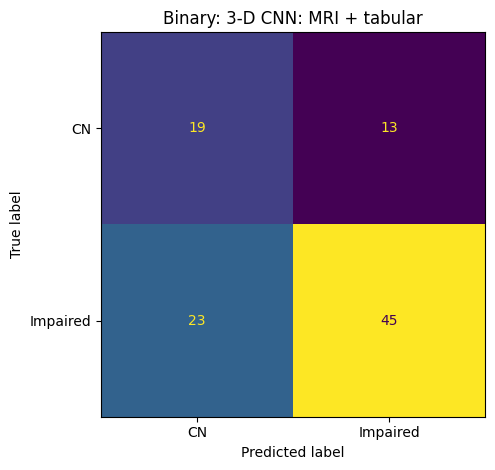

Validation balanced accuracy of MRI-only models: {'ViViT (Section 6)': np.float64(0.334), 'Hybrid CNN+ViViT: MRI only': np.float64(0.333), '3-D CNN: MRI only': np.float64(0.364)}
Encoder used in Section 8: 3-D CNN: MRI only


In [22]:
results = pd.DataFrame(RESULTS).set_index(['task', 'model']).round(3)
display(results)
results.to_csv(os.path.join(OUT_DIR, 'results_v2.csv'))

best_bin = max(BINARY_PROBA, key=lambda k: balanced_accuracy_score(y_bin[test_idx], BINARY_PROBA[k].argmax(1)))
ConfusionMatrixDisplay.from_predictions(y_bin[test_idx], BINARY_PROBA[best_bin].argmax(1), display_labels=BIN_NAMES,
                                        colorbar=False)
plt.title(f'Binary: {best_bin}'); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'confusion_binary_best.png')); plt.show()

# Section 8 uses the MRI-only 3-class model with the best VALIDATION balanced accuracy as its encoder
val_scores = {k: balanced_accuracy_score(y[val_idx], m.predict(make_dataset(val_idx), verbose=0).argmax(1))
              for k, m in MRI_ONLY_3CLASS.items()}
print('Validation balanced accuracy of MRI-only models:', {k: round(v, 3) for k, v in val_scores.items()})
BEST_MRI_NAME = max(val_scores, key=val_scores.get)
BEST_MRI_MODEL = MRI_ONLY_3CLASS[BEST_MRI_NAME]
print('Encoder used in Section 8:', BEST_MRI_NAME)

## 8. Longitudinal model: a subject's scans over time

This section treats the *sequence of visits* as the video, which is the original project idea.

* **Encoder**: the MRI-only model (from Sections 6 / 7b) with the best *validation* balanced accuracy, frozen. It was trained only on training-split subjects, so test subjects remain unseen.
* **Input**: the embeddings of a subject's scans from the first `WINDOW_MONTHS` months (up to `MAX_VISITS` scans). The time of each scan (years since the first scan) is appended as a feature.
* **Label**: **conversion**, meaning the diagnosis at *any later* ADNIMERGE visit is worse than at the first scan (CN → MCI/Dementia or MCI → Dementia). Subjects with no follow-up visit after the window are excluded, because their outcome is unknown.
* **Models**: a GRU over the visit sequence, and a logistic regression on the first scan + demographics/genetics for comparison.

⚠️ This dataset has only a small number of subjects with multiple scans **and** follow-up. Treat these numbers as a pilot study with wide confidence intervals.

In [23]:
WINDOW_MONTHS, MAX_VISITS = 12, 4

encoder = keras.Model(BEST_MRI_MODEL.inputs, BEST_MRI_MODEL.get_layer('mri_embedding').output)
all_ds = (tf.data.Dataset.from_tensor_slices({'mri': X_mri})
            .map(lambda d: {'mri': tf.cast(d['mri'], tf.float32)}).batch(BATCH_SIZE))
emb = encoder.predict(all_ds, verbose=0)
EMB_DIM = emb.shape[1]

split_of = {}
for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    split_of.update({s: name for s in groups[idx]})

seq_rows = []
for ptid, g in data.groupby('PTID'):
    first = g['scan_date'].iloc[0]
    win = g[g['scan_date'] <= first + pd.DateOffset(months=WINDOW_MONTHS)].head(MAX_VISITS)
    base_rank = DX_RANK[win['DX'].iloc[0]]
    if base_rank == DX_RANK['Dementia']:
        continue
    later = adni_dx[(adni_dx['PTID'] == ptid) & (adni_dx['EXAMDATE'] > win['scan_date'].iloc[-1] + pd.Timedelta(days=30))]
    if later.empty:
        continue
    seq_rows.append({'PTID': ptid, 'rows': win.index.to_numpy(),
                     'years': ((win['scan_date'] - first).dt.days / 365.25).to_numpy(),
                     'converted': int(later['DX'].map(DX_RANK).max() > base_rank),
                     'split': split_of[ptid]})
seq = pd.DataFrame(seq_rows)
print(f'{len(seq)} subjects with a scan window and follow-up')
if len(seq):
    print(pd.crosstab(seq['split'], seq['converted'], margins=True))

221 subjects with a scan window and follow-up
converted    0   1  All
split                  
test        24  22   46
train       85  56  141
val         19  15   34
All        128  93  221


In [24]:
def seq_tensor(df):
    X = np.zeros((len(df), MAX_VISITS, EMB_DIM + 1), dtype=np.float32)   # zero rows = padding (masked)
    for i, r in enumerate(df.itertuples()):
        n = len(r.rows)
        X[i, :n, :EMB_DIM] = emb[r.rows]
        X[i, :n, EMB_DIM] = r.years
    return X, df['converted'].to_numpy()


def can_evaluate(df):
    return all(df[df.split == s]['converted'].nunique() == 2 for s in ('train', 'test'))


if len(seq) and can_evaluate(seq):
    tr_df = seq[seq.split != 'test']; te_df = seq[seq.split == 'test']
    Xs_tr, ys_tr = seq_tensor(tr_df); Xs_te, ys_te = seq_tensor(te_df)

    keras.utils.set_random_seed(SEED)
    inp = keras.Input((MAX_VISITS, EMB_DIM + 1))
    h = layers.Masking(0.0)(inp)
    h = layers.GRU(32, dropout=0.2)(h)
    h = layers.Dropout(0.3)(h)
    out = layers.Dense(1, activation='sigmoid')(h)
    gru = keras.Model(inp, out)
    gru.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['AUC'])
    cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=ys_tr)
    gru.fit(Xs_tr, ys_tr, epochs=EPOCHS, batch_size=16, validation_split=0.2, class_weight=dict(enumerate(cw)),
            callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)], verbose=0)
    p_gru = gru.predict(Xs_te, verbose=0).ravel()

    # comparison: first scan only + demographics/genetics, no temporal information
    first_rows = lambda df: np.array([r[0] for r in df['rows']])
    feat = lambda df: np.hstack([emb[first_rows(df)], data.loc[first_rows(df), DEMO_GENETIC].to_numpy(dtype=float)])
    lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                       LogisticRegression(class_weight='balanced', C=0.1, max_iter=5000)).fit(feat(tr_df), ys_tr)
    p_lr = lr.predict_proba(feat(te_df))[:, 1]

    for name, p in [('GRU over visit sequence', p_gru), ('LogReg first scan + demo/genetics', p_lr)]:
        print(f'{name:38s} AUC={roc_auc_score(ys_te, p):.3f}  '
              f'bal_acc={balanced_accuracy_score(ys_te, (p > 0.5).astype(int)):.3f}  (n_test={len(ys_te)})')
else:
    print('Not enough converters / non-converters in both train and test subjects to fit and evaluate '
          'a longitudinal model on this dataset. Report this as a data limitation.')

GRU over visit sequence                AUC=0.659  bal_acc=0.627  (n_test=46)
LogReg first scan + demo/genetics      AUC=0.691  bal_acc=0.627  (n_test=46)


## 9. Time to conversion: Cox proportional-hazards survival model

This replaces v1's Random-Forest "years to AD" regressor, which had three problems:
* it predicted `Years_bl` (the *time of each visit*), not the time to conversion;
* its `event` flag was never set, because ADNIMERGE `DX` uses `'Dementia'`, not `'AD'`;
* it ignored **censoring**: subjects who have not converted *yet* are not "never converted".

Survival analysis handles censoring properly. This uses the **full ADNIMERGE cohort** (clinical + genetic data only), which is much larger than the MRI subset:
* **CN → MCI/Dementia** ("Normal → MCI", as planned in v1)
* **MCI → Dementia**

Baseline MMSE is a legitimate covariate *here*: it measures the current state and is used to forecast a **future** event, so the circularity problem from Section 3 does not apply.


=== CN -> MCI/Dementia: 736 subjects, 147 conversions, median follow-up 4.0 y ===


,hazard_ratio,exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
AGE_AT_VISIT,1.067,1.035,1.101,0.000
SEX_F,0.684,0.475,0.984,0.041
PTEDUCAT,0.934,0.871,1.001,0.053
APOE4,1.766,1.291,2.414,0.000
MMSE,0.934,0.808,1.081,0.360


C-index  train=0.643  test=0.573   (0.5 = random, 1 = perfect ranking)
Predicted median years to conversion for 8 test subjects (inf = <50 % risk within observed range):
      PTID  predicted_median_years  observed_years  converted
002_S_0559                     6.7             3.0          0
002_S_5178                    15.7             6.5          0
003_S_4081                     8.0             5.2          0
003_S_4872                    11.6             9.9          0
003_S_4900                     inf             9.2          0
003_S_5150                     inf             0.5          0
003_S_6259                     7.5             4.0          0
005_S_0602                    15.7             7.4          1



=== MCI -> Dementia: 987 subjects, 379 conversions, median follow-up 3.0 y ===


,hazard_ratio,exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
AGE_AT_VISIT,1.035,1.019,1.052,0.000
SEX_F,1.109,0.876,1.406,0.389
PTEDUCAT,1.010,0.969,1.051,0.646
APOE4,1.813,1.538,2.138,0.000
MMSE,0.776,0.731,0.824,0.000


C-index  train=0.705  test=0.607   (0.5 = random, 1 = perfect ranking)
Predicted median years to conversion for 8 test subjects (inf = <50 % risk within observed range):
      PTID  predicted_median_years  observed_years  converted
002_S_4219                     inf             1.0          0
003_S_1074                     6.5             9.1          1
003_S_2374                     4.0             7.5          0
003_S_6432                     5.7             1.0          0
003_S_6479                     7.9             1.0          0
005_S_4168                     5.1            11.1          0
006_S_4346                     4.0             3.1          1
006_S_6651                     7.9             2.8          0


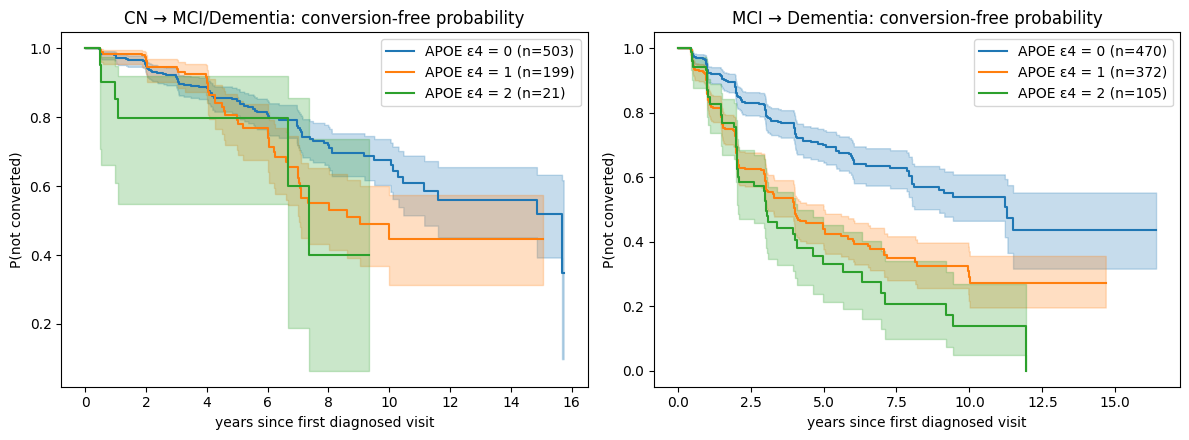

In [25]:
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index

COX_FEATURES = ['AGE_AT_VISIT', 'SEX_F', 'PTEDUCAT', 'APOE4', 'MMSE']


def survival_table(from_dx):
    v = adni_dx.sort_values(['PTID', 'Years_bl'])
    rows = []
    for ptid, g in v.groupby('PTID'):
        if g['DX'].iloc[0] != from_dx:
            continue
        t0 = g['Years_bl'].iloc[0]
        worse = g[g['DX'].map(DX_RANK) > DX_RANK[from_dx]]
        time, event = ((worse['Years_bl'].iloc[0] - t0, 1) if len(worse) else (g['Years_bl'].iloc[-1] - t0, 0))
        if time <= 0:
            continue                      # no follow-up
        rows.append({'PTID': ptid, 'time': time, 'event': event, **g.iloc[0][COX_FEATURES].to_dict()})
    return pd.DataFrame(rows)


def fit_cox(from_dx, target):
    st = survival_table(from_dx)
    print(f'\n=== {from_dx} -> {target}: {len(st)} subjects, {int(st.event.sum())} conversions, '
          f'median follow-up {st.time.median():.1f} y ===')
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(st, groups=st['PTID']))
    st_tr, st_te = st.iloc[tr].copy(), st.iloc[te].copy()
    med = st_tr[COX_FEATURES].median()                           # impute with TRAIN medians only
    st_tr[COX_FEATURES] = st_tr[COX_FEATURES].fillna(med)
    st_te[COX_FEATURES] = st_te[COX_FEATURES].fillna(med)

    cph = CoxPHFitter(penalizer=0.01)
    cph.fit(st_tr[COX_FEATURES + ['time', 'event']], duration_col='time', event_col='event')
    display(cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
              .rename(columns={'exp(coef)': 'hazard_ratio'}).round(3))
    c_test = concordance_index(st_te['time'], -cph.predict_partial_hazard(st_te[COX_FEATURES]), st_te['event'])
    print(f'C-index  train={cph.concordance_index_:.3f}  test={c_test:.3f}   (0.5 = random, 1 = perfect ranking)')

    med_time = cph.predict_median(st_te[COX_FEATURES].head(8))
    print('Predicted median years to conversion for 8 test subjects (inf = <50 % risk within observed range):')
    print(pd.DataFrame({'PTID': st_te['PTID'].head(8).values, 'predicted_median_years': np.round(med_time.values, 1),
                        'observed_years': st_te['time'].head(8).round(1).values,
                        'converted': st_te['event'].head(8).values}).to_string(index=False))
    return st, cph


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (from_dx, target) in zip(axes, [('CN', 'MCI/Dementia'), ('MCI', 'Dementia')]):
    st, cph = fit_cox(from_dx, target)
    for k in sorted(st['APOE4'].dropna().unique()):
        sub = st[st['APOE4'] == k]
        if len(sub) >= 5:
            KaplanMeierFitter().fit(sub['time'], sub['event'], label=f'APOE ε4 = {int(k)} (n={len(sub)})').plot_survival_function(ax=ax)
    ax.set_title(f'{from_dx} → {target}: conversion-free probability')
    ax.set_xlabel('years since first diagnosed visit'); ax.set_ylabel('P(not converted)')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'kaplan_meier_apoe4.png')); plt.show()

## 10. Limitations (state these up front)

1. **Preprocessing**: there is no skull stripping, no bias-field correction and no registration to a template, only reorientation, a head mask, cropping and normalisation. A standard pipeline (e.g. SynthStrip/HD-BET + N4 + ANTs registration to MNI) would reduce scanner and positioning variation.
2. **Sample size**: a few hundred scans from a few hundred subjects is small for a transformer. Results come from one subject-level split. The deep models should ideally be repeated over 5 grouped folds and several seeds (the logistic baselines already are).
3. **Labels**: CN / MCI / Dementia in ADNI are clinical diagnoses, defined partly from cognitive scores. MRI can only be expected to capture part of that signal. The Dementia class may be missing or tiny in this MRI subset.
4. **Slice axis ≠ time**: in Sections 6–7 the ViViT "frames" are slices of one scan. True temporal modelling is only in Sections 8–9, and Section 8 is a small pilot.
5. **Cohort bias**: ADNI participants are mostly white, highly educated volunteers from North American research centres. Results may not generalise to other populations.
6. **Survival model**: Cox regression assumes proportional hazards (check with `cph.check_assumptions(...)`), and ADNI visit schedules make conversion times interval-censored.